# Pneumonia Detection from Chest X-rays: A First Convolutional Neural Network (CNN) in PyTorch

## Introduction

**About this project.** I am currently learning convolutional neural networks (CNNs), and this notebook is my learning project. The goal is to understand every step, from a raw medical image to a trained CNN, and not to build a clinical tool or to climb the Kaggle leaderboard. The network is deliberately small and trained from scratch, so the results are modest. They should be read as *what a first CNN can do*, not as the best that is possible.

The notebook asks one question: **can a small CNN trained from scratch tell, from a single chest X-ray, whether the patient has pneumonia?**

One PyTorch model is built and judged against one "do nothing" baseline:

1. **CNN**: four convolution layers that learn to detect visual patterns (edges, textures, hazy patches), followed by a single linear layer that turns those patterns into one score: pneumonia or not
2. **`always_negative` baseline** (no learning at all): predict "no pneumonia" for every patient

Why the baseline matters: only about 22.5% of the patients have pneumonia, so a model that always says "no pneumonia" is already right about 77.5% of the time. A CNN has to beat that, and it has to find the sick patients, which is why recall and precision are tracked next to accuracy.

What I am practising in this notebook:

| CNN / deep-learning idea | Where it appears |
|---|---|
| Images as arrays and tensors (height, width, channels) | Preparing the data |
| Convolution, ReLU, max pooling, global average pooling | The model |
| Dropout (regularisation) | The model |
| Binary classification with `BCEWithLogitsLoss` | Training |
| Class imbalance, recall and precision | EDA 2, Training, Evaluation |
| Train / validation / test split without leakage | Preparing the data |
| Early stopping and keeping the best weights | Training |
| Confusion matrix and looking at real predictions | Evaluation, Sample predictions |

**Not a medical tool.** This model must never be used to diagnose anyone. It is an exercise in learning how CNNs work.

## Data

**Source:** the RSNA Pneumonia Detection Challenge on Kaggle (chest X-rays labelled by radiologists), downloaded with the Kaggle API.

| File or folder | Content |
|---|---|
| `stage_2_train_labels.csv` | one row per bounding box drawn around a lung opacity, plus one row for every patient without a box. Columns: `patientId`, `x`, `y`, `width`, `height`, `Target` |
| `stage_2_detailed_class_info.csv` | the same rows with a more detailed class name for each X-ray |
| `stage_2_train_images/` | the 26,684 labelled X-rays, one `.dcm` (DICOM) file per patient |
| `stage_2_test_images/` | competition test images **without labels**, so they are not used here |

Because the competition's own test images have no labels, the labelled training images are split into train, validation and test sets later in this notebook.

**What is `Target`?** `Target = 1` means radiologists marked at least one area of lung opacity (the hazy patches that suggest pneumonia). `Target = 0` means no such area was marked.

**DICOM** is the standard file format for medical images. It stores the pixel data and extra information about the scan. The `pydicom` library reads it, and `.pixel_array` returns the image as a NumPy array.

**Setup notes (Google Colab):**

- The Kaggle token is stored in Colab Secrets under the name `KAGGLE_API_TOKEN`, so it never appears in the notebook.
- The competition rules must be accepted on Kaggle once before the download works.
- The zip file is about 3.7 GB (roughly 3 to 4 minutes to download), so this step only needs to run once per session.

In [1]:
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

In [2]:
!pip install -q --upgrade kaggle pydicom
%cd /content
!kaggle competitions download -c rsna-pneumonia-detection-challenge

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 13.5 MB/s eta 0:00:00
/content
100% 3.66G/3.66G [00:28<00:00, 137MB/s]



The zip file is about 3.7 GB (the download took about 30 seconds in this run, but the speed varies), so this step only needs to run once per session.

In [3]:
!unzip -q rsna-pneumonia-detection-challenge.zip -d /content/rsna
!ls /content/rsna

'GCP Credits Request Link - RSNA.txt'   stage_2_test_images
 stage_2_detailed_class_info.csv        stage_2_train_images
 stage_2_sample_submission.csv	        stage_2_train_labels.csv


## Libraries

- `pydicom`: reads the DICOM X-ray files
- `cv2` (OpenCV): resizes the images
- `pandas`, `numpy`, `matplotlib`: tables, arrays and plots
- `train_test_split` (scikit-learn): splits the patients into train, validation and test sets
- `torch`, `torch.nn`: the PyTorch library for building and training the CNN
- `TensorDataset`, `DataLoader`: feed the images to the network in small batches

In [4]:
import numpy as np
import pydicom
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score
import cv2
import torch
import torch.nn as nn
import copy
from torch.utils.data import TensorDataset, DataLoader

## Exploratory analysis

Five quick checks before any modelling: what the label files contain, how balanced the classes are, what is hiding inside the "no pneumonia" group, what the X-rays look like, and what happens to one image when it is shrunk for the CNN.

### EDA 1: the label files

First a data-quality check on the two CSV files: their size, column types, missing values and duplicates.

In [5]:
R = "/content/rsna"
labels = pd.read_csv(f'{R}/stage_2_train_labels.csv')
info = pd.read_csv(f'{R}/stage_2_detailed_class_info.csv')

print(labels.shape, info.shape)
print(labels.dtypes, '\n')
print(labels.isna().sum(), '\n')
print('unique patients:', labels.patientId.nunique(), '| rows:', len(labels))
print('fully duplicated rows:', labels.duplicated().sum())

(30227, 6) (30227, 2)
patientId     object
x            float64
y            float64
width        float64
height       float64
Target         int64
dtype: object 

patientId        0
x            20672
y            20672
width        20672
height       20672
Target           0
dtype: int64 

unique patients: 26684 | rows: 30227
fully duplicated rows: 0


**Result:**

- `stage_2_train_labels.csv` has 30,227 rows but only **26,684 unique patients**. The extra 3,543 rows exist because a patient with pneumonia can have several bounding boxes, one row per box.
- The columns `x`, `y`, `width` and `height` are missing in 20,672 rows. This is not a data error: a patient without pneumonia has no box to describe. The next step shows that 20,672 is exactly the number of patients without pneumonia.
- `Target` has no missing values, and there are no fully duplicated rows.
- Both files have 30,227 rows, so the detailed class information lines up with the labels row by row.

Because the table has several rows for some patients, it cannot be used directly for a split into train and test sets (the same patient could land on both sides). The next step reduces it to **one row per patient**.

### EDA 2: one row per patient and the class balance

`groupby('patientId')['Target'].max()` collapses the table to one row per patient. A patient counts as positive if *any* of their rows has `Target = 1`. The pie chart then shows how the two classes are split.

In [6]:
patients = labels.groupby('patientId')['Target'].max().reset_index()

print(len(labels), 'rows ->', len(patients), 'patients')
print(patients['Target'].value_counts())
print('share with pneumonia:', patients['Target'].mean())

30227 rows -> 26684 patients
Target
0    20672
1     6012
Name: count, dtype: int64
share with pneumonia: 0.225303552690751


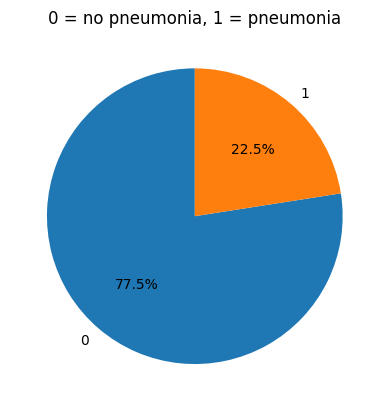

In [7]:
patients['Target'].value_counts().sort_index().plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    ylabel=''
)
plt.title('0 = no pneumonia, 1 = pneumonia')
plt.show()

**Result:**

- 30,227 rows become **26,684 patients**: 20,672 without pneumonia and **6,012 with pneumonia (22.5%)**.
- The classes are imbalanced: negatives outnumber positives by about 3.4 to 1.
- A model that always predicts "negative" reaches about **77.5% accuracy** without looking at a single image. That is the `always_negative` baseline from the introduction.

Consequences for this project:

1. **Accuracy alone is misleading.** A CNN that learns nothing can still score 77.5%.
2. **Recall** (the share of sick patients the model finds) and **precision** (the share of flagged patients who are really sick) are tracked as well. The baseline has a recall of 0, so recall shows clearly whether the CNN has learned anything.
3. The splits are **stratified**, so train, validation and test each keep the same 22.5% share of positives.

### EDA 3: what is inside the "no pneumonia" group?

`stage_2_detailed_class_info.csv` already holds a more detailed class for every X-ray, and it has been loaded but not used yet. Here it splits the patients into three groups:

- **Normal**: a healthy-looking chest X-ray
- **No Lung Opacity / Not Normal**: no pneumonia opacity, but something else looks abnormal
- **Lung Opacity**: the pneumonia group (`Target = 1`)

Why this matters: the "no pneumonia" class is **not** all healthy chests. If a large part of it is "Not Normal", the CNN must separate pneumonia from *other* abnormalities, which is harder than separating sick from healthy. I expect about 8,851 Normal and 11,821 Not Normal patients, which together add up to the 20,672 negatives seen above.

class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012
Name: count, dtype: int64
total patients: 26684


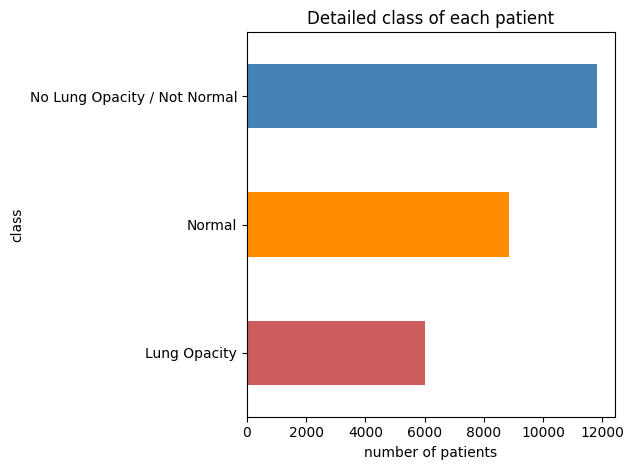

In [8]:
detail = info.drop_duplicates('patientId')['class'].value_counts()
print(detail)
print('total patients:', detail.sum())

detail.plot.barh(color=['steelblue', 'darkorange', 'indianred'][:len(detail)])
plt.xlabel('number of patients')
plt.title('Detailed class of each patient')
plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

### EDA 4: what do the X-rays look like?

Four random patients from each class (`random_state=0` makes the choice reproducible). Row 1 is pneumonia positive, row 2 is pneumonia negative.

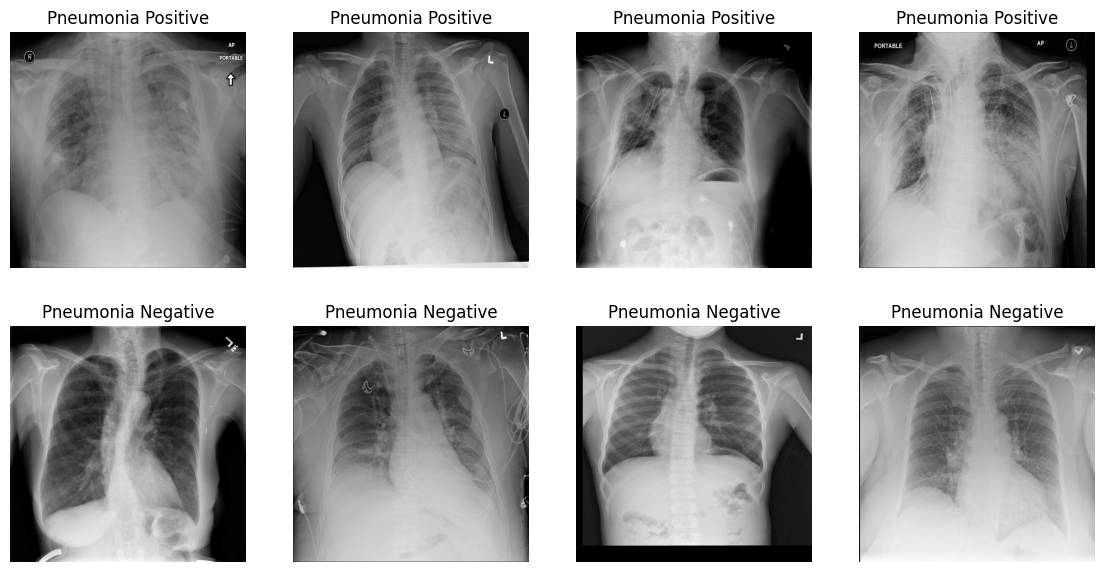

In [9]:
def show(pid, ax, status):
    img = pydicom.dcmread(f'{R}/stage_2_train_images/{pid}.dcm').pixel_array
    ax.set_title(f"{status}")
    ax.imshow(img, cmap='gray')
    ax.axis('off')

sick = patients[patients.Target == 1].patientId.sample(4, random_state=0)
healthy = patients[patients.Target == 0].patientId.sample(4, random_state=0)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, pid in zip(axes[0], sick): show(pid, ax,"Pneumonia Positive")
for ax, pid in zip(axes[1], healthy): show(pid, ax,"Pneumonia Negative")
plt.show()

**Result:**

- The negatives mostly show dark, clear lung fields with visible ribs and vessels.
- The positives typically show **hazy white patches (opacities)** in one or both lungs.
- The difference is often subtle, and some negatives also look cloudy or cluttered, so the classes cannot be separated by eye or by a simple brightness rule. This is exactly the kind of job a CNN is built for: finding local visual patterns.
- Two warnings visible even in these eight images. First, the images differ a lot in framing, brightness and contrast. Second, some carry **text markers** (such as "PORTABLE" or "AP") and **medical devices** (tubes, wires). A CNN can sometimes learn such shortcuts instead of the lungs, because they correlate with how sick a patient is. This is worth remembering when judging the results.

### EDA 5: one raw image, and what resizing costs

The original DICOM images are large (1024 x 1024 pixels). A CNN on full-size images would be slow to train, so every image is shrunk to **150 x 150** before training. The cell below reads one raw X-ray, shows its shape, data type and pixel range, and places it next to its shrunken version. The shrunken image is exactly what the CNN will see.

Expect to keep only about 2% of the original pixels. Large opacities should survive the shrinking, but fine detail will blur. This is a deliberate trade-off between speed and detail, and it is listed again under limitations.

raw  : (1024, 1024) uint8 | pixel range 0 to 255
small: (150, 150) uint8
pixels kept: 2.1 %


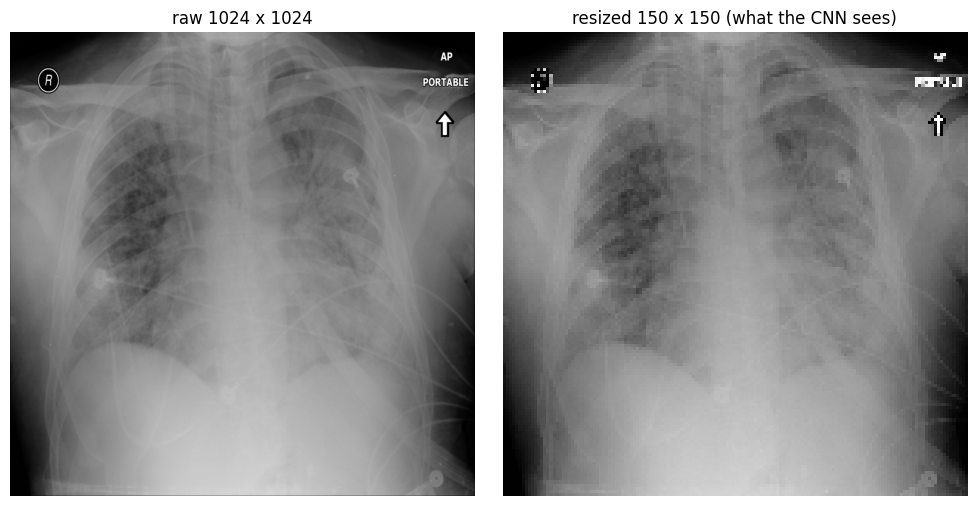

In [10]:
pid = sick.iloc[0]
raw_img = pydicom.dcmread(f'{R}/stage_2_train_images/{pid}.dcm').pixel_array
small = cv2.resize(raw_img, (150, 150))

print('raw  :', raw_img.shape, raw_img.dtype, '| pixel range', raw_img.min(), 'to', raw_img.max())
print('small:', small.shape, small.dtype)
print('pixels kept:', round(small.size / raw_img.size * 100, 1), '%')

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(raw_img, cmap='gray'); ax[0].set_title(f'raw {raw_img.shape[0]} x {raw_img.shape[1]}')
ax[1].imshow(small, cmap='gray');   ax[1].set_title('resized 150 x 150 (what the CNN sees)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### What the EDA means for the modelling

| Finding | Decision |
|---|---|
| Only 22.5% positives | Compare against the 77.5% `always_negative` baseline and track recall and precision, not accuracy alone |
| Several rows per patient | Reduce to one row per patient before splitting, so no patient can appear in two splits |
| "No pneumonia" includes abnormal chests | Expect a hard problem and modest results |
| Subtle visual differences | Use a CNN, which learns local patterns directly from the pixels |
| Large raw images | Shrink to 150 x 150 for speed, and accept some loss of detail |

## Preparing the data for the CNN

### Split: train, validation, test

Each patient is assigned to exactly one set.

| Split | Share | Patients | Used for |
|---|---|---|---|
| Train | 70% | 18,678 | learning the weights |
| Validation | 15% | 4,003 | deciding when to stop training |
| Test | 15% | 4,003 | the final score and the sample predictions, **never touched during training** |

Two details that protect the result:

- **Stratified split** (`stratify=patients['Target']`): every set keeps the same share of pneumonia patients. The check below confirms about 22.5% in each.
- **No leakage:** the split is done on the one-row-per-patient table, and the three `set()` lines printed by the second cell confirm that no patient appears in two sets. Without this, the model could be tested on a patient it has already seen.

The test set is split off *before* any training, and it is only used once, at the end.

In [11]:
train_df, temp_df = train_test_split(
    patients, test_size=0.30, stratify=patients['Target'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['Target'], random_state=42
)

print(len(train_df), len(val_df), len(test_df))

18678 4003 4003


In [12]:
for name, df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, len(df), 'positive share:', round(df['Target'].mean(), 3))

print(set(train_df.patientId) & set(val_df.patientId))
print(set(train_df.patientId) & set(test_df.patientId))
print(set(val_df.patientId) & set(test_df.patientId))

train 18678 positive share: 0.225
val 4003 positive share: 0.225
test 4003 positive share: 0.225
set()
set()
set()


**Result:** the split gives 18,678 / 4,003 / 4,003 patients, each with a positive share of 0.225. All three overlap checks print an empty `set()`, so there is no leakage between the sets.

### Images to arrays

For every patient the function `load_img` reads the DICOM file and shrinks the image to 150 x 150. `build` then stacks all images of a split into one array of shape **(N, 150, 150, 1)**:

- `N`: the number of images
- `150, 150`: height and width in pixels
- `1`: one colour channel, because an X-ray is grayscale (a colour photo would have 3)

The pixels stay as integers from 0 to 255 (`uint8`) to save memory. They are only converted to numbers between 0 and 1 inside the model. Loading all 26,684 images takes about 3 minutes.

In [13]:
def load_img(pid):
    img = pydicom.dcmread(f'{R}/stage_2_train_images/{pid}.dcm').pixel_array
    return cv2.resize(img, (150, 150))

In [14]:
from tqdm import tqdm

def build(df):
    X = np.array([load_img(p) for p in tqdm(df.patientId)], dtype=np.uint8)
    X = X[..., np.newaxis]          # (N,150,150,1) color to grayscale and N = no of images
    y = df['Target'].values
    return X, y

X_train, y_train = build(train_df)
X_val, y_val = build(val_df)
X_test, y_test = build(test_df)

100%|██████████| 4003/4003 [00:27<00:00, 144.98it/s]


(18678, 150, 150, 1) (4003, 150, 150, 1) (4003, 150, 150, 1)
0 255 uint8


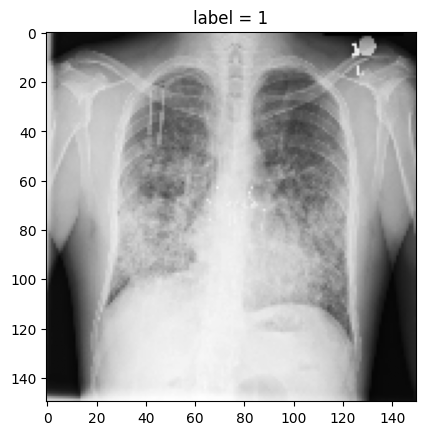

In [15]:
print(X_train.shape, X_val.shape, X_test.shape)
print(X_train.min(), X_train.max(), X_train.dtype)

plt.imshow(X_train[0, :, :, 0], cmap='gray')
plt.title(f'label = {y_train[0]}')
plt.show()

**Result:** the arrays have the shapes (18678, 150, 150, 1), (4003, 150, 150, 1) and (4003, 150, 150, 1), with pixel values from 0 to 255 stored as `uint8`. The plotted image is a grayscale chest X-ray with its label in the title, so the labels and the images still match after loading.

## PyTorch setup

- `device` selects the GPU if one is available and the CPU otherwise. The run saved in this notebook printed `cpu`, which works but is slow. In Colab, **Runtime > Change runtime type > GPU** makes training much faster.
- `make_loader` converts the NumPy arrays into PyTorch tensors and wraps them in a `DataLoader`, which hands the model the data in small batches.

Two details inside `make_loader`:

1. **`permute(0, 3, 1, 2)`** changes the shape from (N, 150, 150, 1) to **(N, 1, 150, 150)**. PyTorch convolutions expect the channel axis *before* height and width.
2. **Labels become floats**, because the loss function compares them with the model's decimal output.

| Loader | Batch size | Shuffled? |
|---|---|---|
| Train | 32 | yes, so every epoch sees the images in a new order |
| Validation | 64 | no |
| Test | 64 | **no**: the order must stay the same as `X_test` and `test_df`, so predictions can be matched back to the right X-ray later |

In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cpu


In [17]:
def make_loader(X, y, shuffle=False, bs=32):
    X = torch.from_numpy(X).permute(0, 3, 1, 2)   # (N,150,150,1) -> (N,1,150,150)
    y = torch.from_numpy(y).float()
    return DataLoader(TensorDataset(X, y), batch_size=bs, shuffle=shuffle)

train_dl = make_loader(X_train, y_train, shuffle=True)
val_dl   = make_loader(X_val, y_val, bs=64)
test_dl  = make_loader(X_test, y_test, bs=64)

## The model

### The idea behind a CNN

A **convolution layer** slides a small window (here 3 x 3 pixels) over the image. Each window position is multiplied by a set of learned numbers called a **filter**, which produces one number. The filter therefore acts as a pattern detector: it responds strongly wherever the image looks like the pattern it has learned. The same filter is reused at every position, so the layer can find a pattern wherever it appears.

Layers are stacked. The first ones tend to pick up simple things (edges, brightness changes). Later ones combine those into larger patterns (textures, shapes). For X-rays the hope is that deeper layers react to hazy patches in the lungs.

A **dense** (fully connected) layer applied to the raw 22,500 pixels would need over 2.8 million weights for just 128 outputs. This whole CNN has **240,385** parameters, because the small filters are shared across the image.

### The building blocks used here

| Block | What it does |
|---|---|
| `Conv2d(in, out, 3, padding=1)` | `out` filters of size 3 x 3. `padding=1` keeps the height and width unchanged |
| `ReLU` | replaces negative numbers with 0, which lets the network learn curved (non-linear) rules |
| `MaxPool2d(2)` | keeps the largest value in every 2 x 2 block, which halves height and width and keeps the strongest responses |
| `AdaptiveAvgPool2d(1)` | averages each feature map to a single number (global average pooling) |
| `Dropout(0.5)` | during training, randomly sets half of the values to 0 so the network cannot rely on any single one, which reduces overfitting. It is switched off for validation and testing |
| `Linear(128, 1)` | turns the 128 numbers into one score |

### What happens inside `forward` (batch of B images)

| Step | Layer | Shape | Meaning |
|---|---|---|---|
| input | `x` | (B, 1, 150, 150) | B grayscale images |
| scale | `x.float() / 255` | (B, 1, 150, 150) | pixel values 0 to 255 become 0 to 1 |
| conv 1 + ReLU | `Conv2d(1, 32, 3)` | (B, 32, 150, 150) | 32 filters, 32 feature maps |
| pool | `MaxPool2d(2)` | (B, 32, 75, 75) | half the height and width |
| conv 2 + ReLU | `Conv2d(32, 64, 3)` | (B, 64, 75, 75) | 64 filters |
| pool | `MaxPool2d(2)` | (B, 64, 37, 37) | 75 / 2 rounded down |
| conv 3 + ReLU | `Conv2d(64, 128, 3)` | (B, 128, 37, 37) | 128 filters |
| pool | `MaxPool2d(2)` | (B, 128, 18, 18) | 37 / 2 rounded down |
| conv 4 + ReLU | `Conv2d(128, 128, 3)` | (B, 128, 18, 18) | 128 filters, no pooling after this one |
| global average pool | `AdaptiveAvgPool2d(1)` | (B, 128, 1, 1) | each feature map becomes its average |
| flatten | `Flatten` | (B, 128) | remove the 1 x 1 axes |
| dropout | `Dropout(0.5)` | (B, 128) | only active during training |
| linear | `Linear(128, 1)` | (B, 1) | one score per image |
| drop the last axis | `.squeeze(1)` | (B,) | one number per image |

The output is a **logit**: a raw score that can be any number, where large positive means "pneumonia" and large negative means "no pneumonia". It is *not* a probability yet. `torch.sigmoid(logit)` converts it into a probability between 0 and 1, and a probability above 0.5 is read as "pneumonia".

### Parameters (the numbers the network learns)

| Layer | Parameters | Calculation |
|---|---|---|
| Conv 1 | 320 | 1 x 32 x 3 x 3 + 32 |
| Conv 2 | 18,496 | 32 x 64 x 3 x 3 + 64 |
| Conv 3 | 73,856 | 64 x 128 x 3 x 3 + 128 |
| Conv 4 | 147,584 | 128 x 128 x 3 x 3 + 128 |
| Linear | 129 | 128 x 1 + 1 |
| **Total** | **240,385** | matches the printed count |

In [18]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, 1))

    def forward(self, x):
        x = x.float() / 255
        x = self.features(x)
        x = self.pool(x)
        return self.head(x).squeeze(1)

model = CNN().to(device)
print(model)
print('parameters:', sum(p.numel() for p in model.parameters()))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)
parameters: 240385


## Training

### Settings

| Setting | Value |
|---|---|
| Loss | `BCEWithLogitsLoss` (binary cross-entropy that takes the raw logit) |
| Optimiser | Adam, learning rate 0.001 |
| Batch size | 32 (train) |
| Maximum epochs | 30 |
| Early stopping | patience 5, judged on the **validation loss** |
| Dropout | 0.5 |
| Decision threshold | 0.5 (probability above 0.5 means "pneumonia") |
| Random seed | not set, so the exact numbers change slightly from run to run |

**Why this loss?** For a yes/no label the loss measures how surprised the model is by the right answer. A confident correct prediction gives a loss near 0, and a confident wrong one gives a large loss. `BCEWithLogitsLoss` applies the sigmoid internally, which is why the model outputs logits.

For every batch of 32 images `run_epoch` does the following:

1. `model(xb)`: forward pass, get the logits
2. `loss_fn(logits, yb)`: compute the loss
3. `opt.zero_grad()`: clear the gradients left over from the last batch
4. `loss.backward()`: backpropagation, work out how each weight affects the loss
5. `opt.step()`: Adam nudges every weight slightly in the helpful direction

For the validation set only steps 1 and 2 run (`train=False`), and no weights change.

After each epoch (one full pass over the 18,678 training images) the validation loss is measured. If it improves, a copy of the weights is saved with `copy.deepcopy`. If it fails to improve for 5 epochs in a row, training stops, and **the best saved weights are reloaded** by the last line, so the model that gets tested is the best one on validation and not simply the last one trained.

### Metrics shown while training

- **Recall** = true positives / (true positives + false negatives): of all patients who really have pneumonia, the share the model finds. If 100 patients are sick and the model finds 40, recall is 0.40.
- **Precision** = true positives / (true positives + false positives): of all patients the model flags, the share who are really sick. If it flags 100 and 65 are sick, precision is 0.65.

Recall matters most here, because missing a sick patient (a false negative) is worse than a false alarm. The `always_negative` baseline has a recall of exactly 0, so any recall above 0 shows that the CNN has learned something.

The training recall and precision are measured while dropout is switched on, so they can look slightly worse than they would on the same images with dropout off. The validation numbers are measured with dropout off.

In [19]:
loss_fn = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

In [20]:
def run_epoch(dl, train=False):
    model.train(train)
    total_loss, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            total_loss += loss.item() * len(xb)
            preds.append((torch.sigmoid(logits) > 0.5).cpu())
            ys.append(yb.cpu())
    preds, ys = torch.cat(preds), torch.cat(ys)
    tp = ((preds == 1) & (ys == 1)).sum().item()
    fp = ((preds == 1) & (ys == 0)).sum().item()
    fn = ((preds == 0) & (ys == 1)).sum().item()
    recall    = tp / (tp + fn) if tp + fn else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    return total_loss / len(ys), recall, precision

### The training loop

The loop below trains for up to 30 epochs, prints the training and validation numbers after each one, and applies early stopping. The last line reloads the best weights, so **let it run to the end** (or until it prints `early stopping`). If training is interrupted by hand, run `model.load_state_dict(best_state)` yourself before evaluating.

In [21]:
history = {k: [] for k in ['loss', 'recall', 'precision', 'val_loss', 'val_recall', 'val_precision']}
best_val, best_state, wait, PATIENCE = float('inf'), None, 0, 5

for epoch in range(30):
    tr = run_epoch(train_dl, train=True)
    va = run_epoch(val_dl)
    for k, v in zip(['loss', 'recall', 'precision'], tr): history[k].append(v)
    for k, v in zip(['val_loss', 'val_recall', 'val_precision'], va): history[k].append(v)
    print(f'epoch {epoch+1:2d} | loss {tr[0]:.3f} rec {tr[1]:.2f} prec {tr[2]:.2f} '
          f'| val_loss {va[0]:.3f} rec {va[1]:.2f} prec {va[2]:.2f}')

    if va[0] < best_val:
        best_val, best_state, wait = va[0], copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print('early stopping'); break

model.load_state_dict(best_state)

epoch  1 | loss 0.523 rec 0.01 prec 0.41 | val_loss 0.515 rec 0.10 prec 0.42
epoch  2 | loss 0.471 rec 0.08 prec 0.57 | val_loss 0.459 rec 0.05 prec 0.57
epoch  3 | loss 0.453 rec 0.15 prec 0.61 | val_loss 0.450 rec 0.10 prec 0.61
epoch  4 | loss 0.447 rec 0.20 prec 0.61 | val_loss 0.442 rec 0.23 prec 0.63
epoch  5 | loss 0.442 rec 0.25 prec 0.62 | val_loss 0.454 rec 0.12 prec 0.68
epoch  6 | loss 0.437 rec 0.27 prec 0.62 | val_loss 0.440 rec 0.16 prec 0.65
epoch  7 | loss 0.436 rec 0.28 prec 0.62 | val_loss 0.453 rec 0.13 prec 0.69
epoch  8 | loss 0.434 rec 0.30 prec 0.63 | val_loss 0.434 rec 0.32 prec 0.61
epoch  9 | loss 0.431 rec 0.32 prec 0.63 | val_loss 0.431 rec 0.27 prec 0.64
epoch 10 | loss 0.428 rec 0.32 prec 0.63 | val_loss 0.434 rec 0.22 prec 0.67
epoch 11 | loss 0.426 rec 0.34 prec 0.63 | val_loss 0.441 rec 0.17 prec 0.70
epoch 12 | loss 0.422 rec 0.36 prec 0.64 | val_loss 0.439 rec 0.19 prec 0.68
epoch 13 | loss 0.422 rec 0.36 prec 0.63 | val_loss 0.444 rec 0.18 prec 0.72

<All keys matched successfully>

In the run saved in this notebook, early stopping never triggered. All 30 epochs ran, and the best validation loss (0.403) came at epoch 30, so the model was still improving when it reached the epoch cap. Training for more epochs would probably help.

### Learning curves

Training and validation loss, recall and precision per epoch. What to look for:

- **Loss:** both curves should fall. If the training loss keeps falling while the validation loss turns upward, the model has started to memorise the training images (overfitting).
- **Recall and precision:** the training curves are smooth, while the validation curves are expected to be jumpy, because every point is measured on a different version of the weights.

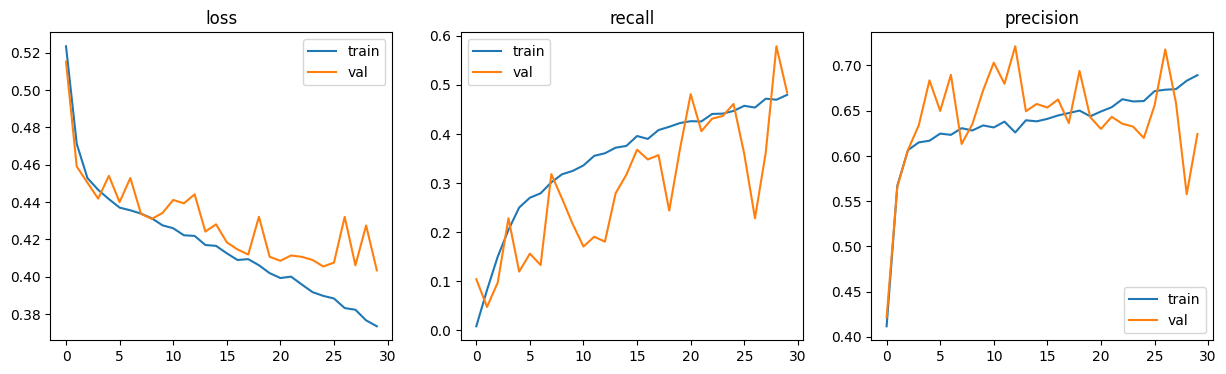

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ['loss', 'recall', 'precision']):
    a.plot(history[m], label='train'); a.plot(history['val_' + m], label='val')
    a.set_title(m); a.legend()
plt.show()

## Evaluation on the test set

From here on all numbers use the **test set**: 4,003 patients that were never used for learning the weights or for early stopping. Every patient gets a probability from the CNN, and a probability above 0.5 is read as "pneumonia".

The **confusion matrix** counts the four possible outcomes:

| | Predicted: no pneumonia | Predicted: pneumonia |
|---|---|---|
| **Truly no pneumonia** | true negative (TN): correct | false positive (FP): false alarm |
| **Truly pneumonia** | false negative (FN): a **missed** sick patient | true positive (TP): correct |

Metrics computed from it:

- **`accuracy`**: the share of all patients classified correctly
- **`recall`**: the share of sick patients found, TP / (TP + FN). It is also called sensitivity
- **`precision`**: the share of flagged patients who are really sick, TP / (TP + FP)
- **`specificity`**: the share of healthy patients correctly cleared, TN / (TN + FP)
- **`roc_auc`**: the chance that a randomly chosen sick patient gets a higher probability than a randomly chosen healthy one. 0.5 means guessing and 1.0 means perfect ranking. It does not depend on the 0.5 threshold

The key reference point is the **`always_negative` baseline**: accuracy equal to the share of negatives (about 77.5%), recall 0, and an AUC of 0.5. A useful model has to clearly beat that on recall and AUC, and not only on accuracy.

,accuracy,recall,precision,specificity,roc_auc
always_negative,0.7747,0.00,0.0000,1.0000,0.5000
CNN,0.8129,0.48,0.6073,0.9097,0.8371


test patients: 4003 | pneumonia: 902 | no pneumonia: 3101


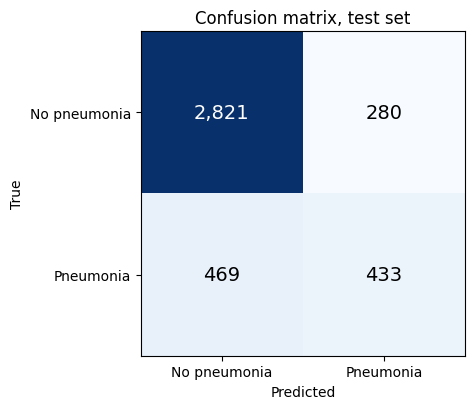

In [23]:
@torch.no_grad()
def predict_proba(dl):
    model.eval()                                   # dropout off
    return torch.cat([torch.sigmoid(model(xb.to(device))).cpu() for xb, _ in dl]).numpy()

test_probs = predict_proba(test_dl)
test_pred  = (test_probs > 0.5).astype(int)

def scores(tn, fp, fn, tp):
    return dict(accuracy    = (tp + tn) / (tp + tn + fp + fn),
                recall      = tp / (tp + fn) if tp + fn else 0.0,
                precision   = tp / (tp + fp) if tp + fp else 0.0,
                specificity = tn / (tn + fp) if tn + fp else 0.0)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
cnn = scores(tn, fp, fn, tp);  cnn['roc_auc'] = roc_auc_score(y_test, test_probs)

n_pos, n_neg = int((y_test == 1).sum()), int((y_test == 0).sum())
base = scores(n_neg, 0, n_pos, 0);  base['roc_auc'] = 0.5     # always predicts "no pneumonia"

display(pd.DataFrame({'always_negative': base, 'CNN': cnn}).T.round(4))
print(f'test patients: {len(y_test)} | pneumonia: {n_pos} | no pneumonia: {n_neg}')

# Confusion matrix plot
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap='Blues')
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, f'{v:,}', ha='center', va='center', fontsize=14,
            color='white' if v > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['No pneumonia', 'Pneumonia']); ax.set_yticks([0, 1], ['No pneumonia', 'Pneumonia'])
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Confusion matrix, test set')
plt.tight_layout(); plt.show()

**Result:**

- Accuracy: **81.3%** for the CNN against **77.5%** for `always_negative`. Judge the gain by recall and AUC, not by accuracy, because accuracy can only gain a few points on top of the baseline.
- Recall: **48%** (the baseline is 0). Read it as "of every 100 pneumonia patients, the CNN finds 48 and misses 52". The validation recall of about 0.35 in the last epochs shown suggests that a large share of sick patients is still missed at the 0.5 threshold.
- Precision: **60.7%**. During training it was around 0.65, so about two out of three flagged patients should really be sick.
- ROC AUC: **83.7%** against 0.5 for guessing. An AUC clearly above 0.5 means the probabilities do rank sick patients above healthy ones, even if the 0.5 threshold is not the best cut-off.
- The confusion matrix shows where the errors are: FN are missed pneumonia cases, FP are false alarms.

## Sample predictions from the test set

Numbers in a table are hard to feel, so here are real test X-rays next to what the CNN said about them.

- **8 random X-rays from the test set**: 4 that truly have pneumonia (top row) and 4 that truly do not (bottom row). The sample is balanced on purpose, because a purely random draw would contain only about 2 sick patients out of 8 and would show little.
- Each title gives the **true label**, the **predicted label** and the model's **probability** of pneumonia.
- **Green** means the prediction is correct and **red** means it is wrong.
- The images are the 150 x 150 versions the CNN actually saw, so they look blurrier than the EDA images.

How to read it: 8 images are far too few to measure accuracy, so they are for building intuition only. The honest score is the table above, computed on all 4,003 test patients. Change the seed (`default_rng(7)`) to look at a different sample.

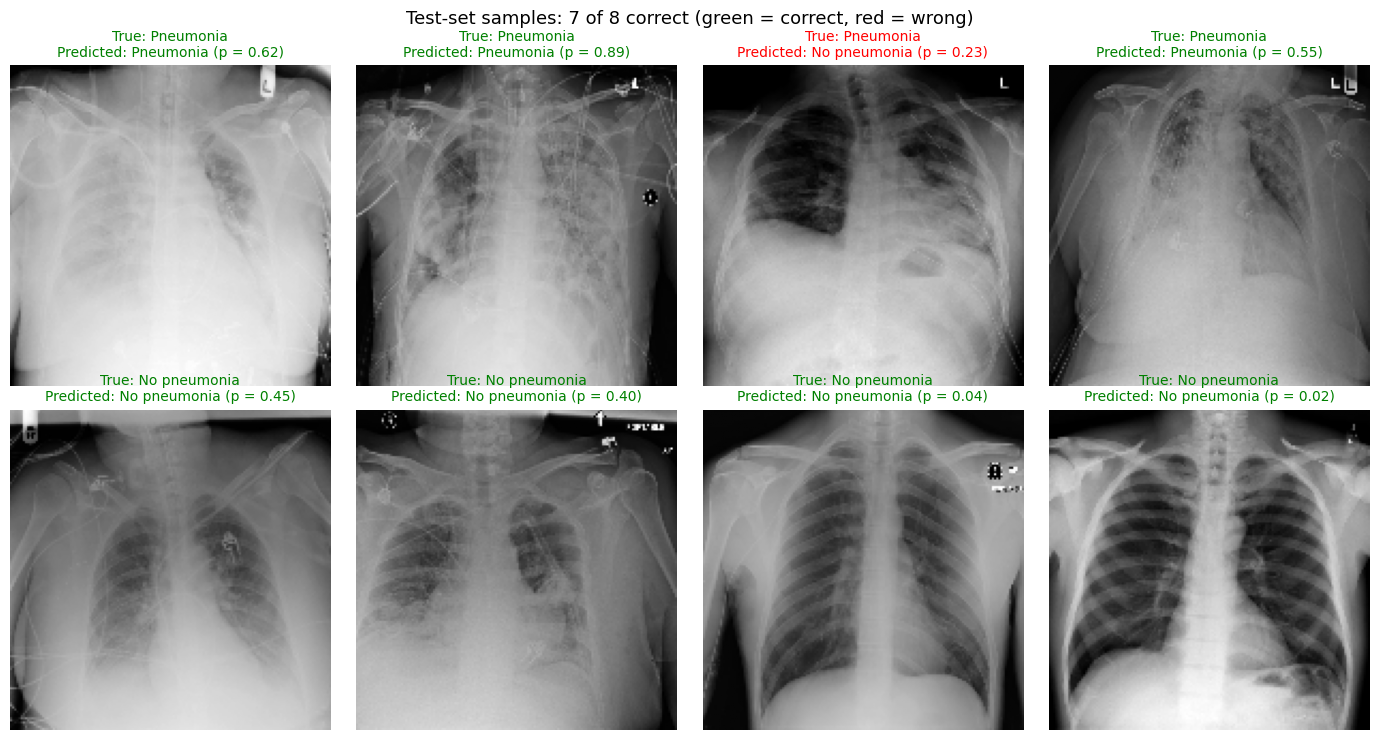

In [24]:
rng = np.random.default_rng(7)
pos_idx = rng.choice(np.where(y_test == 1)[0], 4, replace=False)
neg_idx = rng.choice(np.where(y_test == 0)[0], 4, replace=False)
idx = np.concatenate([pos_idx, neg_idx])

names = {0: 'No pneumonia', 1: 'Pneumonia'}
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
n_correct = 0
for ax, i in zip(axes.ravel(), idx):
    p = test_probs[i]
    pred, true = int(p > 0.5), int(y_test[i])
    ok = pred == true
    n_correct += ok
    ax.imshow(X_test[i, :, :, 0], cmap='gray')
    ax.set_title(f'True: {names[true]}\nPredicted: {names[pred]} (p = {p:.2f})',
                 color='green' if ok else 'red', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Test-set samples: {n_correct} of 8 correct (green = correct, red = wrong)', fontsize=13)
plt.tight_layout(); plt.show()

**Result:**

- In this sample the CNN got 7 of 8 right. That is a handful of images, so it is an illustration and not an accuracy estimate.
- Look at the **probabilities**, not only the colours. A healthy X-ray with p = 0.05 is a confident correct answer. A sick X-ray with p = 0.40 is a *near miss*: the model leaned towards pneumonia but did not cross the 0.5 line.
- Recall: 48% (the baseline is 0). Read it as “of every 100 pneumonia patients, the CNN finds 48 and misses 52”. The validation recall was very jumpy in the last epochs (between 0.23 and 0.58), so the test value of 0.48 is best read as “roughly half”, not as an exact figure. A large share of sick patients is still missed at the 0.5 threshold.
- Precision: 60.7%. During training it was around 0.65 to 0.69, so roughly 3 out of every 5 flagged patients are really sick.
- On the full test set the CNN missed about 469 sick patients (false negatives) and raised about 280 false alarms (false positives), so the typical mistake is missed pneumonia (red titles in the top row) rather than a false alarm (red titles in the bottom row). The CNN is cautious about calling pneumonia.

### Verdict: did the CNN learn something?

| Question | Answer |
|---|---|
| Does the CNN beat `always_negative` on recall? | The baseline has recall 0. The CNN reached 0.48 on the test set, so yes: it finds a real share of sick patients. Validation recall was jumpy in the last epochs (0.23 to 0.58).|
| Does it beat `always_negative` on accuracy? | Only by a few points above 77.5%. Test accuracy: 81.3 % |
| Does the ranking carry signal? | ROC AUC on the test set: 0.84 (guessing = 0.5) |
| Overfitting? | No clear sign of it: training loss (0.373) and validation loss (0.403) are close, though the gap widens slightly in the last epochs, so it is worth watching if training runs longer|
| Biggest weakness | About half of the sick patients are missed at the 0.5 threshold (test recall 0.48) |

**Conclusion:** a small CNN trained from scratch on 150 x 150 images **does learn to find pneumonia**: its recall is far above the baseline's 0 and its precision is reasonable. It is nowhere near a reliable screening tool, because it still misses many sick patients. That is a sensible outcome for a first CNN with 240,385 parameters and a few minutes of training.

**What I learned about CNNs from this project:**

1. **Shapes are everything.** Most of the work was keeping track of (N, H, W, C) versus (N, C, H, W) and how each layer changes the size.
2. **Accuracy can lie.** With 22.5% positives, the baseline already scores 77.5%, so recall and precision told the real story.
3. **Splitting by patient matters.** Several rows per patient would have leaked information between the sets.
4. **Logits, sigmoid and thresholds are three separate things.** The model outputs a raw score, the sigmoid turns it into a probability, and the threshold turns that into a decision. Changing the threshold trades recall against precision without retraining.
5. **Looking at real predictions is useful.** A table says "recall 0.35", but the sample grid shows which X-rays are missed.

### Limitations and next steps

- **Small images.** At 150 x 150 only about 2% of the original pixels are kept, so subtle opacities can disappear. Next: try 224 x 224 or larger.
- **Trained from scratch.** With 18,678 images and no pretraining the CNN has to learn everything from zero. Next: **transfer learning** with a network already trained on millions of images (for example ResNet or DenseNet from `torchvision`).
- **No data augmentation.** The CNN sees every training image in exactly one form. Next: small random rotations, brightness and contrast changes, and zoom, which usually reduce overfitting and help recall.
- **Fixed 0.5 threshold and unweighted loss.** The classes are imbalanced and recall is low. Next: pick the threshold on the *validation* set using a precision-recall curve, or give positives more weight with `BCEWithLogitsLoss(pos_weight=...)`.
- **Possible shortcuts.** Text markers ("PORTABLE") and medical devices correlate with illness (see EDA 4). Next: **Grad-CAM** heat maps to check whether the CNN looks at the lungs.
- **Mixed negatives.** The "no pneumonia" class includes X-rays with other abnormalities (EDA 3), which makes the task harder than healthy versus sick.
- **Bounding boxes are unused.** The data says *where* the opacities are, but this model only answers *whether* there is one. Next: object detection (for example Faster R-CNN or YOLO).
- **One run, no seed.** Results change a little each run. Next: fix `torch.manual_seed` and repeat with several seeds, as in my stock-return notebook, to see how much of a result is luck.
- **Not a medical device.** Nothing here has been clinically validated.
- Training stopped at the epoch cap. The validation loss was still falling at epoch 30, so the model is probably under-trained. Next: raise the maximum number of epochs and let early stopping decide when to stop.